# Instrumental Variables and Regression Discontinuity

**What you'll learn**

- Why unobserved confounding defeats regression adjustment, and how an **encouragement design**
  (a randomized push notification that nudges feature adoption) rescues causal inference — simulated
  with known ground truth so every estimator can be checked against the answer.
- The four IV conditions (relevance, independence, exclusion, monotonicity) translated into plain
  business language, and which of them you can actually test.
- **2SLS by hand** (two OLS stages), via a library, and via the Wald ratio — plus why the estimand is the
  **LATE** (compliers' effect), not the ATE, and why that distinction changes rollout forecasts.
- What **weak instruments** do to 2SLS — bias toward OLS, wild tails — demonstrated by shrinking the
  first stage across hundreds of simulated experiments, and what the first-stage F rule of thumb buys you.
- How an **exclusion violation** (the push itself nudges the outcome) biases IV by `direct effect / first stage`,
  so weak instruments *amplify* exclusion violations.
- **Sharp RD** at a spend threshold for a loyalty discount: local linear estimation, bandwidth sensitivity,
  placebo cutoffs, a McCrary-style density check for manipulation, and the fuzzy-RD-is-IV connection.

**Why it matters in interviews**

- "Adopters of feature X retain better — does X cause retention?" is a staple senior DS/AS case.
  The strong answer proposes an encouragement design and correctly interprets what it identifies.
- IV questions probe whether you understand *identification* vs *estimation*: anyone can run 2SLS;
  seniors defend exclusion, check the first stage, and say "LATE" unprompted.
- RDD comes up wherever thresholds exist (credit score cutoffs, spend tiers, ranking positions,
  eligibility rules) — interviewers test whether you know when it's credible and how to falsify it.
- Weak-instrument pathologies are a classic follow-up ("your F is 4 — now what?").

Prerequisites from this module: potential-outcomes and DAG language from
[01_potential_outcomes_dags.ipynb](01_potential_outcomes_dags.ipynb); selection-on-observables methods
(what to reach for when confounders *are* measured) in
[02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb); panel-based designs in
[03_did_synthetic_control.ipynb](03_did_synthetic_control.ipynb). IV and RDD complete the
quasi-experimental toolkit: they handle *unobserved* confounding, at the price of stronger design
requirements and a more local estimand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.sandbox.regression.gmm import IV2SLS

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.dpi": 100,
})

## 1. The problem: unobserved confounding defeats regression adjustment

**Business setting.** A streaming app shipped a "smart playlists" feature. Adoption is voluntary.
The PM observes that adopters are far more active next month and wants to credit the feature.
The obvious confounder is **latent engagement** $U$: engaged users both adopt new features *and*
retain — and no logged covariate measures $U$ exactly. In the DAG language of
[01_potential_outcomes_dags.ipynb](01_potential_outcomes_dags.ipynb), the backdoor path
$D \leftarrow U \rightarrow Y$ cannot be blocked, because $U$ is unobserved. Propensity scores and
regression (notebook 02) are helpless here: they only adjust for what you measure.

**The rescue: an encouragement design.** Growth randomly sends a push notification $Z$ that
advertises the feature. The push is randomized, cheap, and moves adoption. That makes $Z$ an
**instrument** for adoption $D$, with outcome $Y$ = active days next month.

The simulated data-generating process (so we know every truth):

- $U \sim N(0,1)$: latent engagement (never available to the analyst).
- $Z \sim \text{Bernoulli}(0.5)$: randomized push.
- Adoption index $W = 1.2\,U + e_d$. Without the push a user adopts iff $W > 1.0$; with the push
  iff $W > 1.0 - \gamma$ (encouragement strength $\gamma = 0.9$). Same $W$ in both worlds
  $\Rightarrow$ **monotonicity holds by construction** (the push never talks anyone out of adopting).
- Heterogeneous true effect $\tau_i = 2.0 + 1.5\,U$ active days: engaged users get more out of the
  feature. So the ATE is 2.0 days, but subpopulations differ — that's deliberate.
- Outcome $Y = 12 + 3.5\,U + \tau_i D + \varepsilon$: engagement directly drives retention
  (the confounding), on top of the causal effect of adoption.
- `x_hist` = a *noisy proxy* of engagement (standardized past sessions) — the kind of covariate you
  actually have. Controlling for it will reduce but not remove the bias.

In [2]:
def draw_encouragement(size, gamma=0.9, delta=0.0, rng=rng):
    """Encouragement-design DGP. `size` may be an int or (reps, n) for vectorized experiments.

    gamma: encouragement strength (drives the first stage / complier share).
    delta: DIRECT effect of the push on the outcome (0 = exclusion holds).
    """
    U = rng.normal(0.0, 1.0, size)                    # latent engagement (unobserved)
    Z = rng.integers(0, 2, size).astype(float)        # randomized push notification
    W = 1.2 * U + rng.normal(0.0, 1.0, size)          # adoption index
    D0 = (W > 1.0).astype(float)                      # would adopt without the push
    D1 = (W > 1.0 - gamma).astype(float)              # would adopt with the push (>= D0: monotone)
    D = np.where(Z == 1.0, D1, D0)                    # observed adoption
    tau_i = 2.0 + 1.5 * U                             # heterogeneous true effect (active days)
    Y = 12.0 + 3.5 * U + tau_i * D + delta * Z + rng.normal(0.0, 4.0, size)
    return {"U": U, "Z": Z, "W": W, "D0": D0, "D1": D1, "D": D, "tau_i": tau_i, "Y": Y}


N = 40_000
users = pd.DataFrame(draw_encouragement(N))
users["x_hist"] = users["U"] + rng.normal(0.0, 1.0, N)   # observable, noisy engagement proxy
users["ctype"] = np.select(
    [users["D0"] == 1, (users["D0"] == 0) & (users["D1"] == 1)],
    ["always-taker", "complier"], default="never-taker",
)

ate_true = users["tau_i"].mean()
late_true = users.loc[users["ctype"] == "complier", "tau_i"].mean()
print(f"n = {N:,} users | adoption rate: {users['D'].mean():.1%}")
print(f"true ATE  (all users):  {ate_true:.2f} active days")
print(f"true LATE (compliers):  {late_true:.2f} active days")
print(users["ctype"].value_counts(normalize=True).round(3).to_string())

n = 40,000 users | adoption rate: 36.8%
true ATE  (all users):  2.01 active days
true LATE (compliers):  2.41 active days
ctype
never-taker     0.524
always-taker    0.262
complier        0.214


### Regression does not save you

Naive OLS of $Y$ on $D$ inherits the full confounding. Adding the best available covariate
(`x_hist`, a noisy engagement proxy) shrinks the bias but cannot eliminate it — measurement error
in the proxy leaves a residual open backdoor. This is the practical point interviewers want:
*"we controlled for everything we log" is not the same as "we controlled for the confounder."*

In [3]:
ols_naive = smf.ols("Y ~ D", data=users).fit(cov_type="HC1")
ols_proxy = smf.ols("Y ~ D + x_hist", data=users).fit(cov_type="HC1")
print(f"true LATE {late_true:.2f} / true ATE {ate_true:.2f}")
print(f"OLS  Y ~ D            : {ols_naive.params['D']:.2f}  (SE {ols_naive.bse['D']:.2f})")
print(f"OLS  Y ~ D + x_hist   : {ols_proxy.params['D']:.2f}  (SE {ols_proxy.bse['D']:.2f})")
print("Both are far above any true effect: adopters were going to retain better anyway.")

true LATE 2.41 / true ATE 2.01
OLS  Y ~ D            : 7.35  (SE 0.06)
OLS  Y ~ D + x_hist   : 5.41  (SE 0.06)
Both are far above any true effect: adopters were going to retain better anyway.


## 2. The IV conditions, in business language

| Condition | Plain-language version (this example) | Testable? |
|---|---|---|
| **Relevance** | The push genuinely moves adoption. | **Yes** — regress $D$ on $Z$, read the first-stage coefficient and F. |
| **Independence** | The push was assigned by coin flip, so it's unrelated to who users are. | Mostly — verify randomization like an A/B test (SRM checks, covariate balance; see [../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)). |
| **Exclusion** | The push affects next-month activity **only** by causing adoption — reading the notification does nothing by itself. | **No** — untestable with one instrument. Must be argued from design (this is where IVs die). |
| **Monotonicity** | The push never *prevents* anyone from adopting (no "defiers" who adopt only if left alone). | No — argued from psychology/UX. Usually plausible for encouragements. |

Exclusion deserves the scrutiny. A push notification that says *"try smart playlists"* also reminds
the user the app exists — a direct $Z \to Y$ path. Section 5 quantifies exactly how much that costs.

### First stage, ITT, and the Wald estimator

With a single binary instrument and no covariates, IV has a closed form — the **Wald ratio**:

$$\hat\tau_{IV} \;=\; \frac{E[Y\mid Z=1]-E[Y\mid Z=0]}{E[D\mid Z=1]-E[D\mid Z=0]} \;=\; \frac{\text{ITT}}{\text{first stage}}$$

The numerator is the **intent-to-treat** effect — exactly what an A/B test of the push measures.
The denominator rescales it: the push only moved adoption for compliers, so dividing by the complier
share converts "effect of *offering*" into "effect of *adopting*, for those moved by the offer."

In [4]:
first = smf.ols("D ~ Z", data=users).fit(cov_type="HC1")
reduced = smf.ols("Y ~ Z", data=users).fit(cov_type="HC1")
fs_hat = first.params["Z"]
itt_hat = reduced.params["Z"]
F_first = (first.params["Z"] / first.bse["Z"]) ** 2
wald = itt_hat / fs_hat

print(f"first stage (adoption lift from push): {fs_hat:.3f}   [first-stage F = {F_first:,.0f}]")
print(f"ITT on active days (the A/B readout) : {itt_hat:.3f}")
print(f"Wald = ITT / first stage             : {wald:.2f}   (true LATE {late_true:.2f})")

first stage (adoption lift from push): 0.209   [first-stage F = 1,981]
ITT on active days (the A/B readout) : 0.497
Wald = ITT / first stage             : 2.37   (true LATE 2.41)


### 2SLS by hand, then with a library

Two-stage least squares generalizes the Wald ratio to covariates and multiple instruments:

1. **Stage 1:** regress $D$ on $Z$ (+ exogenous controls); keep fitted values $\hat D$ —
   the part of adoption *explained by the coin flip*, purged of $U$.
2. **Stage 2:** regress $Y$ on $\hat D$ (+ the same controls). The coefficient on $\hat D$ is the IV estimate.

Running the two stages manually is the best way to understand the estimator — and a classic way to get
**wrong standard errors** in production: stage 2's OLS SEs treat $\hat D$ as data, ignoring that the
residual should be built from the *actual* $D$. Always report SEs from an IV routine
(here `statsmodels`' `IV2SLS`; `linearmodels.iv.IV2SLS` is the fuller industry option with robust/clustered SEs).

In [5]:
# --- 2SLS by hand: two OLS stages ---
users["D_hat"] = first.fittedvalues
stage2 = smf.ols("Y ~ D_hat", data=users).fit()

# --- library 2SLS ---
iv_lib = IV2SLS(
    users["Y"].to_numpy(),
    sm.add_constant(users["D"].to_numpy()),   # endog regressor D (+ const)
    sm.add_constant(users["Z"].to_numpy()),   # instrument Z (+ const)
).fit()

summary = pd.DataFrame(
    {
        "estimate": [ols_naive.params["D"], ols_proxy.params["D"], wald,
                     stage2.params["D_hat"], iv_lib.params[1]],
        "SE": [ols_naive.bse["D"], ols_proxy.bse["D"], np.nan,
               stage2.bse["D_hat"], iv_lib.bse[1]],
    },
    index=["OLS (naive)", "OLS + proxy control", "Wald ratio",
           "2SLS by hand (stage-2 OLS SE)", "IV2SLS library"],
)
print(summary.round(3))
print(f"\ntruth: LATE = {late_true:.2f}, ATE = {ate_true:.2f}")
print("Wald = hand 2SLS = library 2SLS (same point estimate); only the library SE is trustworthy.")

                               estimate     SE
OLS (naive)                       7.349  0.056
OLS + proxy control               5.412  0.055
Wald ratio                        2.373    NaN
2SLS by hand (stage-2 OLS SE)     2.373  0.302
IV2SLS library                    2.373  0.275

truth: LATE = 2.41, ATE = 2.01
Wald = hand 2SLS = library 2SLS (same point estimate); only the library SE is trustworthy.


**Reading the table.** OLS is biased upward by a factor of ~3 (7.35 vs the true LATE of 2.41); the
proxy control removes barely a third of that bias; the three IV computations agree with each other
and with the truth (within one SE). The hand-rolled stage-2 SE (0.30) is *not* the correct IV SE
(0.28) — close here, but only by accident of the DGP, so never report it. Note also that the IV SE
is ~5x the OLS SE: that variance cost is the price of identification, and it's why IV needs big
samples — **you're only using the experimentally induced sliver of variation in adoption.**

### Who are the compliers? LATE vs ATE

IV with a binary instrument identifies the **Local Average Treatment Effect**: the effect *for users
whose adoption was changed by the push*. Three latent groups coexist (no defiers, by monotonicity):

- **Always-takers** — power users who adopt regardless. The push tells us nothing about them.
- **Never-takers** — disengaged users who won't adopt even when pushed. Also invisible to IV.
- **Compliers** — the persuadable middle. The entire IV estimate comes from them.

In the simulation we can peek at the latent types (in real data you can't, but you can profile
compliers on observables via Abadie's $\kappa$-weighting):

In [6]:
prof = (
    users.groupby("ctype")
    .agg(share=("ctype", "size"), mean_engagement_U=("U", "mean"),
         mean_x_hist=("x_hist", "mean"), true_mean_effect=("tau_i", "mean"))
    .assign(share=lambda d: d["share"] / len(users))
    .loc[["never-taker", "complier", "always-taker"]]
)
print(prof.round(3))
print(f"\n2SLS estimate {iv_lib.params[1]:.2f} matches compliers' truth {late_true:.2f},"
      f" not the ATE {ate_true:.2f}")

              share  mean_engagement_U  mean_x_hist  true_mean_effect
ctype                                                                
never-taker   0.524             -0.582       -0.573             1.127
complier      0.214              0.272        0.290             2.408
always-taker  0.262              0.960        0.959             3.440

2SLS estimate 2.37 matches compliers' truth 2.41, not the ATE 2.01


The ordering is exactly what you'd guess: always-takers are the most engaged and benefit most,
never-takers the least. Compliers sit in between — so here LATE > ATE (by ~0.4 days), and a forecast
that treats the 2SLS number as "the effect of adoption for everyone" overstates a forced rollout.
We quantify that mistake in the Pitfalls section. Heterogeneous-effect estimation is the subject of
[05_uplift_cate.ipynb](05_uplift_cate.ipynb).

## 3. Weak instruments: shrinking the first stage

The Wald denominator is an *estimate*. When the true first stage is small, the estimated denominator
rattles around zero: 2SLS becomes heavy-tailed, biased toward OLS, and its normal-approximation CIs
lie. We rerun the whole experiment 500 times at n = 2,000 for four encouragement strengths $\gamma$,
tracking the first-stage F and the 2SLS estimate each time.

Note a subtlety worth saying in an interview: as $\gamma$ shrinks, **the estimand itself moves** —
a weaker push persuades only users right at the adoption margin, so the complier population (and its
true LATE) changes. Weak instruments are doubly awkward: worse estimation *and* a narrower question.

In [7]:
def iv_experiments(reps, n, gamma, delta=0.0, seed=0):
    """Vectorized replications: Wald/2SLS estimate, first-stage F, OLS, per-config true LATE."""
    r = np.random.default_rng(seed)
    d = draw_encouragement((reps, n), gamma=gamma, delta=delta, rng=r)
    Z, D, Y = d["Z"], d["D"], d["Y"]
    n1 = Z.sum(axis=1)
    n0 = n - n1
    y1, y0 = (Y * Z).sum(1) / n1, (Y * (1 - Z)).sum(1) / n0
    p1, p0 = (D * Z).sum(1) / n1, (D * (1 - Z)).sum(1) / n0
    fs = p1 - p0
    with np.errstate(divide="ignore"):     # an estimated first stage of exactly 0 => ±inf estimate:
        iv = (y1 - y0) / fs                # that IS the weak-instrument pathology, keep it visible
    resid = D - np.where(Z == 1, p1[:, None], p0[:, None])       # first-stage residuals
    s2 = (resid ** 2).sum(1) / (n - 2)
    F = fs ** 2 / (s2 * n / (n1 * n0))                           # F = t^2 of first-stage slope
    Dc = D - D.mean(1, keepdims=True)
    Yc = Y - Y.mean(1, keepdims=True)
    ols = (Dc * Yc).sum(1) / (Dc ** 2).sum(1)
    comp = d["D1"] > d["D0"]
    late = (d["tau_i"] * comp).sum() / comp.sum()                # truth for this gamma
    return pd.DataFrame({"iv": iv, "F": F, "ols": ols}), late


gammas = [0.9, 0.3, 0.15, 0.05]
dists, rows = {}, []
for i, g in enumerate(gammas):
    res, late_g = iv_experiments(reps=500, n=2_000, gamma=g, seed=100 + i)
    dists[g] = res
    rows.append({
        "gamma": g, "true_LATE": late_g, "median_F": res["F"].median(),
        "pct_F<10": 100 * (res["F"] < 10).mean(),
        "median_2SLS": res["iv"].median(),
        "IQR_2SLS": res["iv"].quantile(0.75) - res["iv"].quantile(0.25),
        "pct_|est|>20": 100 * (res["iv"].abs() > 20).mean(),
        "median_OLS": res["ols"].median(),
    })
weak_tbl = pd.DataFrame(rows)
print(weak_tbl.round(2).to_string(index=False))

 gamma  true_LATE  median_F  pct_F<10  median_2SLS  IQR_2SLS  pct_|est|>20  median_OLS
  0.90       2.39    101.75       0.0         2.37      1.50           0.0        7.32
  0.30       2.63     10.61      44.2         2.83      5.64           1.0        7.78
  0.15       2.69      2.57      94.2         3.20     11.19          12.8        7.89
  0.05       2.70      0.57      99.4         6.85     19.89          32.4        7.95


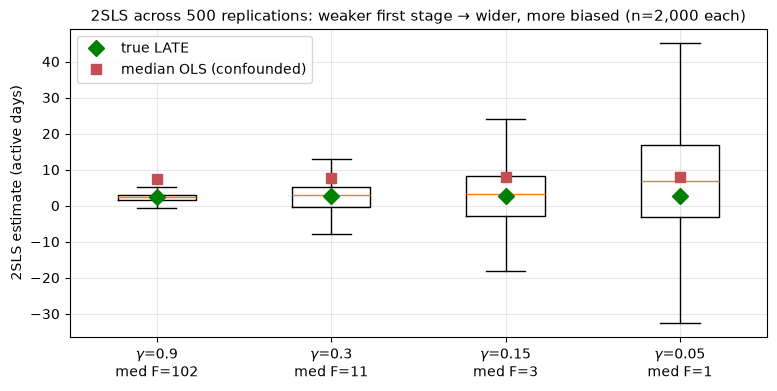

In [8]:
fig, ax = plt.subplots()
ax.boxplot([dists[g]["iv"] for g in gammas], showfliers=False,
           tick_labels=[f"$\\gamma$={g}\nmed F={dists[g]['F'].median():.0f}" for g in gammas])
for pos, g in enumerate(gammas, start=1):
    late_g = weak_tbl.loc[weak_tbl["gamma"] == g, "true_LATE"].iloc[0]
    ax.plot(pos, late_g, "D", color="green", ms=8, zorder=5,
            label="true LATE" if pos == 1 else None)
    ax.plot(pos, dists[g]["ols"].median(), "s", color="#c44e52", ms=7, zorder=5,
            label="median OLS (confounded)" if pos == 1 else None)
ax.set_ylabel("2SLS estimate (active days)")
ax.set_title("2SLS across 500 replications: weaker first stage → wider, more biased (n=2,000 each)")
ax.legend(loc="upper left")
plt.show()

**What the table and plot show.**

- $\gamma=0.9$ (median F ≈ 100): 2SLS is centered on the truth with a tolerable IQR.
- $\gamma=0.3$ (median F ≈ 11 — right at the folk threshold): noticeably wider, still roughly centered.
- $\gamma=0.15$ and $0.05$ (F ≈ 3 and below 1): the estimator falls apart — the median drifts toward the
  confounded OLS value, the IQR explodes, and a chunk of replications produce absurd estimates
  (|est| > 20 days on a 28-day-max metric) because the estimated first stage crossed zero.

**The rule of thumb and its modern update.** "First-stage F > 10" (Staiger–Stock) limits the
worst-case 2SLS bias to roughly 10% of the OLS bias. It is a *minimum*, not a certificate: Lee et al.
(2022) show conventional t-based 95% CIs need F ≈ 100+ to actually cover at 95% without adjustment.
The senior answers when F is low: (a) get a stronger instrument or more sample; (b) report the ITT,
which is always valid under randomization; (c) use weak-instrument-robust inference
(Anderson–Rubin CIs), which stays valid at any F.

## 4. Exclusion violation: when the push acts on the outcome directly

Suppose the notification itself re-engages users — opening the app to dismiss it, a brand reminder —
worth $\delta$ extra active days *regardless of adoption*. Then the ITT numerator picks up $\delta$
that has nothing to do with the feature, and IV converges to

$$\text{plim}\;\hat\tau_{IV} \;=\; \text{LATE} \;+\; \frac{\delta}{\text{first stage}}.$$

The direct effect is **divided by the first stage**: with a 21% complier share, every 0.1 day of
direct push effect becomes ~0.5 days of bias. A weak instrument makes the same violation several
times worse. We simulate $\delta \in \{0, 0.25, 0.5, 1.0\}$ under a strong ($\gamma=0.9$) and a
moderate ($\gamma=0.3$) first stage and compare medians to the analytic bias line.

 gamma  delta  true_LATE  med_2SLS   q25   q75  analytic_plim
   0.9   0.00       2.39      2.44  1.70  2.86           2.39
   0.9   0.25       2.39      3.46  3.09  3.99           3.56
   0.9   0.50       2.39      4.79  4.24  5.27           4.73
   0.9   1.00       2.39      7.09  6.58  7.50           7.08
   0.3   0.00       2.63      2.76  0.85  4.36           2.63
   0.3   0.25       2.62      6.79  5.08  8.22           6.41
   0.3   0.50       2.61      9.87  8.39 11.86          10.19
   0.3   1.00       2.62     17.27 15.54 19.15          17.77


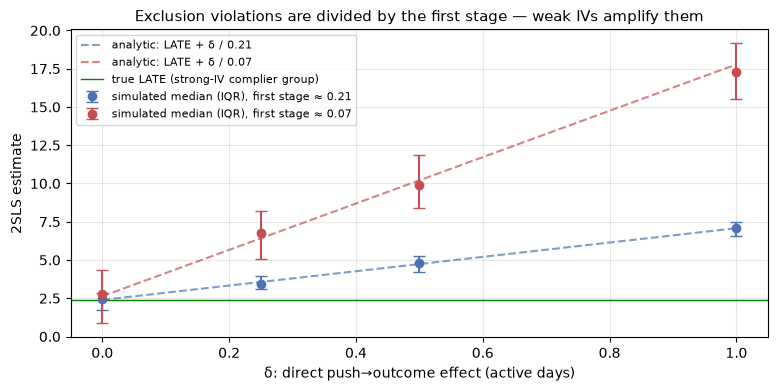

In [9]:
sd_W = np.sqrt(1.2**2 + 1.0)
fs_pop = {g: stats.norm.cdf(1.0 / sd_W) - stats.norm.cdf((1.0 - g) / sd_W) for g in [0.9, 0.3]}
deltas = [0.0, 0.25, 0.5, 1.0]

excl_rows = []
for j, g in enumerate([0.9, 0.3]):
    for k, dl in enumerate(deltas):
        res, late_g = iv_experiments(reps=200, n=4_000, gamma=g, delta=dl, seed=500 + 10 * j + k)
        excl_rows.append({"gamma": g, "delta": dl, "true_LATE": late_g,
                          "med_2SLS": res["iv"].median(),
                          "q25": res["iv"].quantile(0.25), "q75": res["iv"].quantile(0.75),
                          "analytic_plim": late_g + dl / fs_pop[g]})
excl = pd.DataFrame(excl_rows)
print(excl.round(2).to_string(index=False))

fig, ax = plt.subplots()
for g, color in [(0.9, "#4c72b0"), (0.3, "#c44e52")]:
    sub = excl[excl["gamma"] == g]
    ax.errorbar(sub["delta"], sub["med_2SLS"],
                yerr=[sub["med_2SLS"] - sub["q25"], sub["q75"] - sub["med_2SLS"]],
                fmt="o", color=color, capsize=4,
                label=f"simulated median (IQR), first stage ≈ {fs_pop[g]:.2f}")
    dd = np.linspace(0, 1.0, 50)
    ax.plot(dd, sub["true_LATE"].iloc[0] + dd / fs_pop[g], "--", color=color, alpha=0.7,
            label=f"analytic: LATE + δ / {fs_pop[g]:.2f}")
ax.axhline(late_true, color="green", lw=1, label="true LATE (strong-IV complier group)")
ax.set_xlabel("δ: direct push→outcome effect (active days)")
ax.set_ylabel("2SLS estimate")
ax.set_title("Exclusion violations are divided by the first stage — weak IVs amplify them")
ax.legend(fontsize=8)
plt.show()

A direct effect of just 0.5 days — plausible for any notification — pushes the "moderate" IV to
nearly quadruple the true effect (≈9.9 days vs a true 2.6). Design implications for real
encouragement experiments:
make the encouragement as **content-neutral** as possible, use a control push (both arms get *a*
notification, only one mentions the feature) so the direct channel differences out, and always
sanity-check the ITT among never-adopters if you can approximate them.

## 5. Sharp regression discontinuity: a loyalty-tier spend threshold

**Business setting.** Customers whose last-quarter spend reaches **$500** are automatically upgraded
to Gold tier, which applies a 10% discount. Did the discount raise this-quarter spend? Comparing
Gold vs non-Gold customers is hopeless (Gold customers spend more by construction), but the *rule*
creates a natural experiment: a customer at \$499 and one at \$501 are essentially identical, yet
only one gets the discount. The causal contrast at the cutoff is the RD estimand.

Identification requires **continuity**: all other determinants of the outcome vary smoothly through
the threshold — nothing else jumps at exactly \$500, and customers can't precisely sort themselves
across it. The DGP: running variable $X$ = last-quarter spend, outcome $Y$ = this-quarter spend
$= g(X) + \tau\,\mathbf{1}[X \ge 500] + \varepsilon$ with a smooth concave $g$ and **true effect
$\tau = 40$ dollars at the cutoff**.

In [10]:
CUTOFF, TAU_RD = 500.0, 40.0
rd_rng = np.random.default_rng(17)   # dedicated stream so the RD case study reproduces on its own


def simulate_rdd(n, cutoff=CUTOFF, tau=TAU_RD, manipulated=False, fuzzy=False, rng=rng):
    """Loyalty-threshold RD. manipulated: some customers just below the cutoff top up their spend
    to cross it (and are higher-loyalty types). fuzzy: the discount is a voucher redeemed by 62%."""
    X = 80.0 + rng.gamma(2.0, 200.0, n)                       # last-quarter spend ($)
    strategic = np.zeros(n, dtype=bool)
    if manipulated:
        strategic = (X >= cutoff - 30) & (X < cutoff) & (rng.random(n) < 0.5)
        X = np.where(strategic, cutoff + rng.uniform(0, 20, n), X)
    above = (X >= cutoff).astype(float)
    treated = above * (rng.random(n) < 0.62) if fuzzy else above.copy()
    g_X = 60.0 + 0.68 * X + 150.0 * np.log(X / 100.0)         # smooth, concave baseline
    Y = g_X + tau * treated + 30.0 * strategic + rng.normal(0.0, 60.0, n)
    return pd.DataFrame({"X": X, "above": above, "Dt": treated, "Y": Y, "strategic": strategic})


def rd_fit(df, cutoff, h, outcome="Y", kernel="triangular"):
    """Local linear RD: WLS of outcome on side dummy x centered running variable within |X-c| <= h."""
    win = df.loc[(df["X"] - cutoff).abs() <= h].copy()
    win["Xc"] = win["X"] - cutoff
    win["right"] = (win["Xc"] >= 0).astype(float)
    w = 1.0 - win["Xc"].abs() / h if kernel == "triangular" else np.ones(len(win))
    res = smf.wls(f"{outcome} ~ right * Xc", data=win, weights=w).fit(cov_type="HC1")
    return res.params["right"], res.bse["right"], len(win), res


shop = simulate_rdd(30_000, rng=rd_rng)
est, se, n_win, res_main = rd_fit(shop, CUTOFF, h=75)
print(f"{len(shop):,} customers; {n_win:,} within $75 of the cutoff")
print(f"local linear RD (h=$75, triangular): {est:.1f}  (SE {se:.1f})   truth: {TAU_RD:.0f}")

30,000 customers; 5,844 within $75 of the cutoff
local linear RD (h=$75, triangular): 39.1  (SE 3.5)   truth: 40


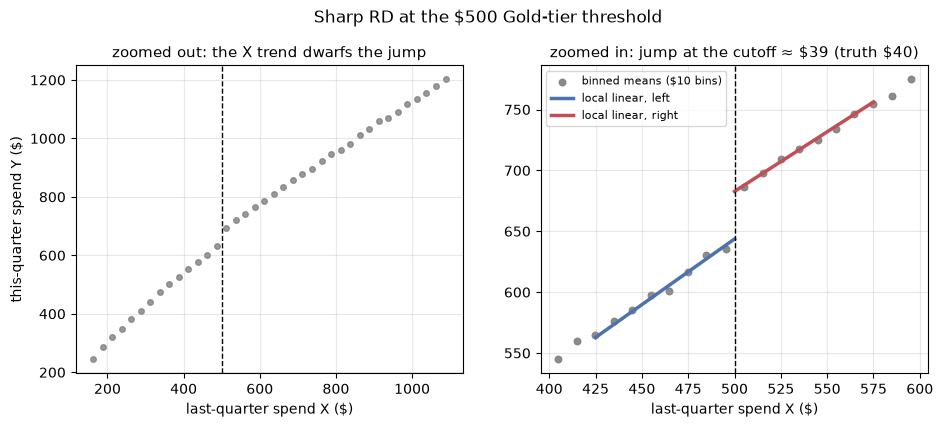

In [11]:
h = 75.0
p = res_main.params
xl = np.linspace(CUTOFF - h, CUTOFF, 60)
xr = np.linspace(CUTOFF, CUTOFF + h, 60)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
wide = (
    shop.assign(bin=lambda d: pd.cut(d["X"], np.arange(150, 1101, 25)))
    .groupby("bin", observed=True).agg(x=("X", "mean"), y=("Y", "mean")).dropna()
)
axes[0].scatter(wide["x"], wide["y"], s=16, color="gray", alpha=0.8)
axes[0].axvline(CUTOFF, color="k", ls="--", lw=1)
axes[0].set_xlabel("last-quarter spend X ($)")
axes[0].set_ylabel("this-quarter spend Y ($)")
axes[0].set_title("zoomed out: the X trend dwarfs the jump")

zoom = (
    shop.loc[shop["X"].between(CUTOFF - 100, CUTOFF + 100)]
    .assign(bin=lambda d: pd.cut(d["X"], np.arange(400, 601, 10)))
    .groupby("bin", observed=True).agg(x=("X", "mean"), y=("Y", "mean")).dropna()
)
axes[1].scatter(zoom["x"], zoom["y"], s=22, color="gray", alpha=0.9, label="binned means ($10 bins)")
axes[1].plot(xl, p["Intercept"] + p["Xc"] * (xl - CUTOFF),
             color="#4c72b0", lw=2.5, label="local linear, left")
axes[1].plot(xr, p["Intercept"] + p["right"] + (p["Xc"] + p["right:Xc"]) * (xr - CUTOFF),
             color="#c44e52", lw=2.5, label="local linear, right")
axes[1].axvline(CUTOFF, color="k", ls="--", lw=1)
axes[1].set_xlabel("last-quarter spend X ($)")
axes[1].set_title(f"zoomed in: jump at the cutoff ≈ \\${est:.0f} (truth \\${TAU_RD:.0f})")
axes[1].legend(fontsize=8)
fig.suptitle("Sharp RD at the $500 Gold-tier threshold", y=1.02)
plt.show()

### Why "local"? Naive alternatives fail

Two tempting shortcuts, both wrong:

- **Global above/below comparison** — dominated by the fact that high-$X$ customers spend more
  next quarter anyway; the "estimate" is mostly the slope of $g$, not the discount.
- **Global OLS with a linear control for $X$** — better, but any curvature in $g$ that a single
  straight line misses gets dumped into the treatment coefficient.

Local linear regression on each side, weighted toward the cutoff, is the standard: it only asks the
model to be approximately linear over a narrow window.

In [12]:
naive_global = shop.loc[shop["above"] == 1, "Y"].mean() - shop.loc[shop["above"] == 0, "Y"].mean()
global_lin = smf.ols("Y ~ above + X", data=shop).fit(cov_type="HC1")
print(f"truth at cutoff:                     {TAU_RD:6.1f}")
print(f"global mean(above) - mean(below):    {naive_global:6.1f}   <- mostly the X trend")
print(f"global OLS, linear X control:        {global_lin.params['above']:6.1f}"
      f"   (SE {global_lin.bse['above']:.1f})  <- curvature leaks in")
print(f"local linear, h=$75:                 {est:6.1f}   (SE {se:.1f})")

truth at cutoff:                       40.0
global mean(above) - mean(below):     495.8   <- mostly the X trend
global OLS, linear X control:          65.7   (SE 1.5)  <- curvature leaks in
local linear, h=$75:                   39.1   (SE 3.5)


### Bandwidth sensitivity — the core bias–variance dial

Small bandwidth: little bias (linearity holds locally) but few customers → noisy. Large bandwidth:
tight SEs but the linear approximation of $g$ degrades → bias. A credible RD writeup **always shows
the estimate as a function of bandwidth**. In production use a data-driven optimal bandwidth
(Imbens–Kalyanaraman, Calonico–Cattaneo–Titiunik — the `rdrobust` package) and report robust
bias-corrected CIs; here we hand-roll to keep the mechanics visible.

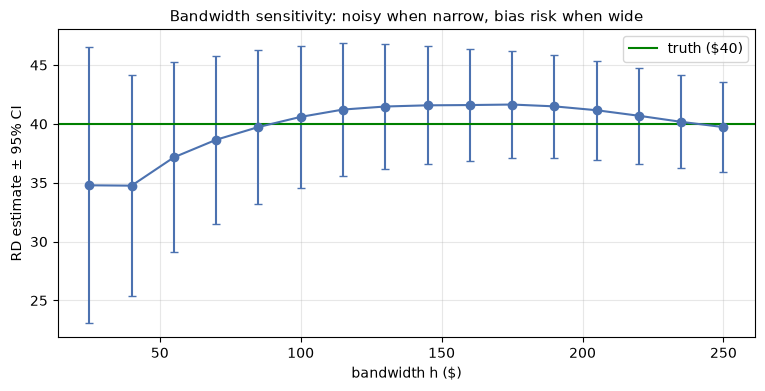

In [13]:
bw = pd.DataFrame([
    dict(zip(["h", "est", "se", "n"], (h_, *rd_fit(shop, CUTOFF, h_)[:3])))
    for h_ in np.arange(25, 251, 15)
])
fig, ax = plt.subplots()
ax.errorbar(bw["h"], bw["est"], yerr=1.96 * bw["se"], fmt="o-", capsize=3, color="#4c72b0")
ax.axhline(TAU_RD, color="green", lw=1.5, label="truth ($40)")
ax.set_xlabel("bandwidth h ($)")
ax.set_ylabel("RD estimate ± 95% CI")
ax.set_title("Bandwidth sensitivity: noisy when narrow, bias risk when wide")
ax.legend()
plt.show()

### Placebo cutoffs — estimating jumps where there shouldn't be any

If the design is sound, running the identical estimator at thresholds where *no rule exists* should
return ~0. Systematic non-zero placebo jumps mean your functional form or data are lying to you.
We test cutoffs at least $100 away from \$500 so no placebo window overlaps the real discontinuity.

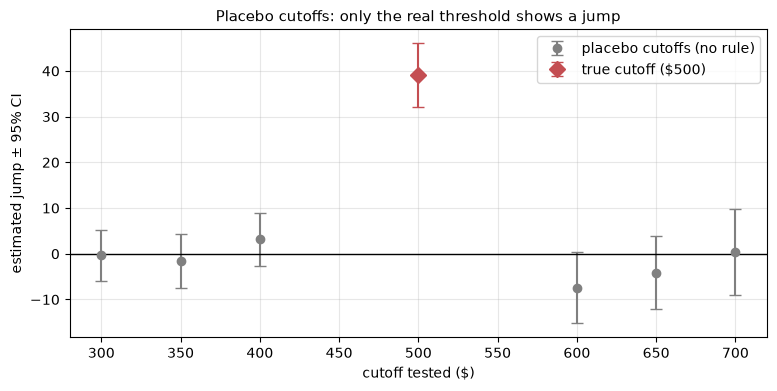

 cut  est  se
 300 -0.3 2.9
 350 -1.5 3.0
 400  3.1 3.0
 600 -7.4 4.0
 650 -4.1 4.1
 700  0.4 4.8


In [14]:
placebo_cuts = [300, 350, 400, 600, 650, 700]
plc = pd.DataFrame([
    dict(zip(["cut", "est", "se"], (c_, *rd_fit(shop, c_, 75)[:2]))) for c_ in placebo_cuts
])
fig, ax = plt.subplots()
ax.errorbar(plc["cut"], plc["est"], yerr=1.96 * plc["se"], fmt="o", capsize=4,
            color="gray", label="placebo cutoffs (no rule)")
ax.errorbar([CUTOFF], [est], yerr=[1.96 * se], fmt="D", capsize=4, ms=8,
            color="#c44e52", label="true cutoff ($500)")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("cutoff tested ($)")
ax.set_ylabel("estimated jump ± 95% CI")
ax.set_title("Placebo cutoffs: only the real threshold shows a jump")
ax.legend()
plt.show()
print(plc.round(1).to_string(index=False))

### The McCrary density check: is anyone gaming the threshold?

RD's Achilles heel is **precise manipulation of the running variable**. If customers near \$490 know
the rule, some will add one more item to cross \$500 — and *those* customers are systematically
different (deal-aware, more engaged). The observable signature is a **discontinuity in the density
of $X$ at the cutoff**: missing mass just below, a spike just above. McCrary's test (and the modern
Cattaneo–Jansson–Ma `rddensity` version) formalizes this; the histogram is the first thing to look at.

We simulate it: half the customers within \$30 below the threshold top up to just above it, and these
strategic types carry a +\$30 loyalty premium in next-quarter spend *unrelated to the discount*.

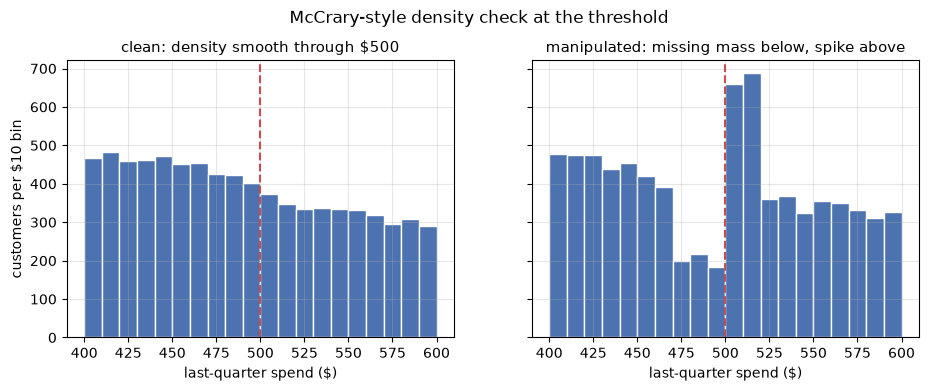

clean        counts  [470,500): 1248   [500,530): 1055   ratio hi/lo: 0.85
manipulated  counts  [470,500):  598   [500,530): 1708   ratio hi/lo: 2.86

RD estimate, clean data:       39.1  (SE 3.5)
RD estimate, manipulated data: 51.8  (SE 3.9)   truth: 40


In [15]:
shop_m = simulate_rdd(30_000, manipulated=True, rng=rd_rng)
est_m, se_m, _, _ = rd_fit(shop_m, CUTOFF, h=75)

hist_bins = np.arange(400, 601, 10)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax_, df_, ttl in [(axes[0], shop, "clean: density smooth through $500"),
                      (axes[1], shop_m, "manipulated: missing mass below, spike above")]:
    ax_.hist(df_.loc[df_["X"].between(400, 600), "X"], bins=hist_bins,
             color="#4c72b0", edgecolor="white")
    ax_.axvline(CUTOFF, color="#c44e52", ls="--", lw=1.5)
    ax_.set_xlabel("last-quarter spend ($)")
    ax_.set_title(ttl)
axes[0].set_ylabel("customers per $10 bin")
fig.suptitle("McCrary-style density check at the threshold", y=1.02)
plt.show()

for df_, lbl in [(shop, "clean"), (shop_m, "manipulated")]:
    lo = df_["X"].between(470, 500, inclusive="left").sum()
    hi = df_["X"].between(500, 530, inclusive="left").sum()
    print(f"{lbl:12s} counts  [470,500): {lo:4d}   [500,530): {hi:4d}   ratio hi/lo: {hi/lo:.2f}")
print(f"\nRD estimate, clean data:       {est:.1f}  (SE {se:.1f})")
print(f"RD estimate, manipulated data: {est_m:.1f}  (SE {se_m:.1f})   truth: {TAU_RD:.0f}")

The manipulated data *look* fine in a scatter, but the density gives it away — and the RD estimate is
inflated because the just-above-cutoff group is now enriched with high-loyalty strategic types.
Complementary check: predetermined covariates (tenure, past frequency) must be smooth at the cutoff
too — Exercise 2 shows covariate balance catching exactly this manipulation.

### Fuzzy RD is IV (briefly)

Suppose Gold status only issues a **voucher**, and 62% of eligible customers redeem it. Crossing the
threshold no longer *sets* treatment — it *jumps the probability* of treatment. That is an
encouragement design at the cutoff: instrument = $\mathbf{1}[X \ge 500]$, and

$$\hat\tau_{\text{fuzzy}} = \frac{\text{jump in } Y \text{ at } c}{\text{jump in } P(\text{treated}) \text{ at } c}$$

— a local Wald ratio, estimating the LATE **for cutoff compliers** (would-redeemers near \$500).
Everything from sections 2–4 applies: check the first-stage jump, worry about weak-IV behavior if
redemption barely moves, and interpret locally (twice local: near the cutoff *and* among compliers).

In [16]:
shop_f = simulate_rdd(30_000, fuzzy=True, rng=rd_rng)
jump_y = rd_fit(shop_f, CUTOFF, 75, outcome="Y", kernel="uniform")
jump_d = rd_fit(shop_f, CUTOFF, 75, outcome="Dt", kernel="uniform")
print(f"jump in Y at cutoff:            {jump_y[0]:6.1f}")
print(f"jump in P(redeemed) at cutoff:  {jump_d[0]:6.3f}")
print(f"fuzzy RD = ratio of jumps:      {jump_y[0] / jump_d[0]:6.1f}   truth: {TAU_RD:.0f}")

# same thing as explicit 2SLS within the window (instrument = side-of-cutoff dummy)
win = shop_f.loc[(shop_f["X"] - CUTOFF).abs() <= 75].copy()
win["Xc"] = win["X"] - CUTOFF
win["right"] = (win["Xc"] >= 0).astype(float)
win["rXc"] = win["right"] * win["Xc"]
iv_rd = IV2SLS(
    win["Y"].to_numpy(),
    sm.add_constant(win[["Dt", "Xc", "rXc"]].to_numpy()),
    sm.add_constant(win[["right", "Xc", "rXc"]].to_numpy()),
).fit()
print(f"2SLS in the window:             {iv_rd.params[1]:6.1f}  (SE {iv_rd.bse[1]:.1f})  — identical estimator")

jump in Y at cutoff:              25.4
jump in P(redeemed) at cutoff:   0.640
fuzzy RD = ratio of jumps:        39.7   truth: 40
2SLS in the window:               39.7  (SE 5.0)  — identical estimator


## 6. Pitfalls

**Pitfall 1 — trusting the second-stage OLS standard errors from manual 2SLS.** Shown in section 2:
the hand-rolled stage-2 SE differs from the correct IV SE because its residuals use $\hat D$ instead
of $D$. The point estimate is fine; the inference is not. Use an IV routine, and in product data
cluster the SEs at the randomization unit (see [../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb)).
The same class of error — "predict, then pretend the prediction is data" — is the *forbidden
regression* when people substitute nonlinear (e.g. logistic) first-stage fits into stage 2:
2SLS's consistency argument relies on OLS-projection algebra, so keep stage 1 linear.

**Pitfall 2 — high-order global polynomials in RD.** Gelman & Imbens (2019) showed global
polynomial RD puts huge, sign-flipping weights on observations far from the cutoff; the estimate
becomes an artifact of the degree you picked.

In [17]:
shop["Xk"] = (shop["X"] - CUTOFF) / 100.0        # rescaled to keep powers well-conditioned
poly_rows = []
for deg in range(1, 6):
    terms = " + ".join(f"I(Xk**{k})" for k in range(1, deg + 1))
    r = smf.ols(f"Y ~ above * ({terms})", data=shop).fit(cov_type="HC1")
    poly_rows.append({"global poly degree": deg, "estimate": r.params["above"], "SE": r.bse["above"]})
poly_tbl = pd.DataFrame(poly_rows)
print(poly_tbl.round(1).to_string(index=False))
print(f"\nlocal linear (h=$75): {est:.1f} (SE {se:.1f});  truth {TAU_RD:.0f}")
print(f"global-poly estimates span {poly_tbl['estimate'].min():.1f} to {poly_tbl['estimate'].max():.1f}"
      " — the degree, an arbitrary choice, moves the answer.")

 global poly degree  estimate  SE
                  1      33.4 1.3
                  2      50.6 1.7
                  3      39.7 2.2
                  4      43.4 2.8
                  5      39.7 3.3

local linear (h=$75): 39.1 (SE 3.5);  truth 40
global-poly estimates span 33.4 to 50.6 — the degree, an arbitrary choice, moves the answer.


**Pitfall 3 — quoting the LATE as if it were the effect for everyone.** The 2SLS number describes
compliers. Forecasting a *forced* rollout ("auto-enable smart playlists for all users") with the
LATE ignores that never-takers — who would now be dragged in — benefit far less.

In [18]:
never_effect = prof.loc["never-taker", "true_mean_effect"]
print(f"LATE (what 2SLS gives you):            {late_true:.2f} days")
print(f"true ATE (forced rollout, everyone):   {ate_true:.2f} days")
print(f"true effect for never-takers:          {never_effect:.2f} days")
print(f"LATE-based forecast overstates a forced rollout by "
      f"{100 * (late_true / ate_true - 1):.0f}% on average, and by "
      f"{100 * (late_true / never_effect - 1):.0f}% for the users it would newly force in.")

LATE (what 2SLS gives you):            2.41 days
true ATE (forced rollout, everyone):   2.01 days
true effect for never-takers:          1.13 days
LATE-based forecast overstates a forced rollout by 20% on average, and by 114% for the users it would newly force in.


**Pitfall 4 — bandwidth (and cutoff) shopping.** With a grid of defensible bandwidths, an analyst
who picks the most flattering one after looking is p-hacking (see
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).
Prespecify a data-driven bandwidth rule and *publish the whole sensitivity curve*, not one point.

In [19]:
z = (bw["est"] / bw["se"]).abs()
print(f"across h in [25, 250]: estimates range {bw['est'].min():.1f} to {bw['est'].max():.1f}")
print(f"most flattering h = {bw.loc[z.idxmax(), 'h']:.0f} (|z| = {z.max():.1f}); "
      f"least = {bw.loc[z.idxmin(), 'h']:.0f} (|z| = {z.min():.1f})")
print("Honest reporting: the full curve from the bandwidth-sensitivity plot, with a prespecified rule.")

across h in [25, 250]: estimates range 34.8 to 41.6
most flattering h = 250 (|z| = 20.3); least = 25 (|z| = 5.8)
Honest reporting: the full curve from the bandwidth-sensitivity plot, with a prespecified rule.


## 7. Interview corner

**Q1. The PM says: "Feature adopters retain 40% better than non-adopters, so the feature drives
retention. Ship a campaign."** — Critique and propose designs.
*Strong answer:* Self-selection: engaged users both adopt and retain; the comparison is confounded by
unobservables, and controlling for logged covariates only partially closes the backdoor. Designs, in
order of strength: (1) randomized **encouragement** (push/email/badge) → IV/2SLS for the adoption
effect, ITT for the campaign effect; (2) feature **holdback** (randomize availability) → clean ATE of
access; (3) staggered rollout → DiD ([03_did_synthetic_control.ipynb](03_did_synthetic_control.ipynb)).
Bonus points: note what each identifies — holdback gives access-ATE, encouragement gives adoption-LATE.

**Q2. Explain IV to a non-statistician.**
*Strong answer:* "We can't compare adopters to non-adopters — they're different people. So we flip a
coin and *invite* a random half. The invitation moves adoption a little, at random. We then measure
how much retention moved and divide by how much adoption moved. Because the only reason those users
adopted was our coin flip, the ratio is the causal effect of adoption for the users the invite
persuaded." Skip "exclusion restriction" language; say "the invite must not help retention on its own."

**Q3. When is RDD credible? What makes you distrust one?**
*Strong answer:* Credible when the cutoff rule is sharp and enforced, agents can't precisely control
their running variable, nothing else changes at the same threshold, and there's enough data near the
cutoff. Distrust: density jump at the cutoff (McCrary), covariate imbalance at the cutoff, estimates
that swing with bandwidth, other policies sharing the threshold (e.g. \$500 also triggers free
shipping), heaping/rounding in the running variable.

**Q4. Your first-stage F is 4. What do you do?**
*Strong answer:* Don't report conventional 2SLS CIs — with F this low the estimate is biased toward
OLS and t-based inference undercovers. Options: strengthen the instrument (better encouragement,
pooled experiments), report the ITT which remains valid, use Anderson–Rubin weak-IV-robust CIs, and
be honest that the complier population is tiny so even a valid estimate answers a narrow question.

**Q5. ITT vs LATE vs ATE in an encouragement design — which does the business want?**
*Strong answer:* ITT = effect of the *nudge policy* (what you get if you ship the push to everyone) —
usually the decision-relevant number for the campaign. LATE = effect of *adoption* for persuadable
users — the right input for valuing further adoption-driving work. ATE of adoption is not identified
without extra assumptions; don't promise it. Forecast rollouts with ITT × population, not LATE × population.

**Q6. How could the exclusion restriction fail here, and what would you do?**
*Strong answer:* The push itself may re-engage users (reminder effect), or annoy them (negative direct
effect). Mitigations: neutral control push in both arms so the direct channel cancels; vary
encouragement intensity and check estimate stability; bound the bias: it's δ divided by the first
stage, so report how big δ would need to be to zero out the finding.

**Q7. What's a fuzzy RD and how do you estimate it?**
*Strong answer:* Crossing the threshold shifts treatment *probability* rather than setting it
(voucher redemption, compliance with an eligibility rule). Estimate = local jump in outcome divided
by local jump in treatment probability — i.e., 2SLS near the cutoff with the side-of-cutoff dummy as
instrument. Interprets as LATE for cutoff compliers; needs a healthy first-stage jump.

## 8. Key takeaways

- Regression adjustment fails exactly when the confounder is unmeasured; proxies shrink, never
  remove, the bias. IV and RDD trade "measure everything" for **design-based** identification.
- Encouragement designs are the practical IV in product work: randomize the *nudge*, instrument the
  *behavior*. ITT / first stage = Wald = 2SLS with one binary instrument.
- IV identifies the **LATE** — the compliers' effect. Say so, and never forecast forced rollouts
  with it: use ITT × population for nudge policies.
- Relevance is testable (first-stage F); exclusion is not — it is argued, stress-tested, and bounded.
  An exclusion violation biases IV by δ / first-stage, so weak instruments amplify it.
- First-stage F > 10 is a floor, not a certificate; F ≈ 100 is the modern comfort zone for
  conventional CIs, and Anderson–Rubin inference is the fallback. Weak IVs are biased toward OLS
  with wild tails — and they change the estimand (a different, more marginal complier group).
- 2SLS point estimates can be computed as two OLS stages, but the stage-2 SEs are wrong — use an IV
  routine, keep the first stage linear, cluster appropriately.
- Sharp RD compares limits at a threshold via **local linear** fits: show the binned scatter, the
  bandwidth-sensitivity curve, placebo cutoffs, a density (McCrary) check, and covariate smoothness.
  Avoid global high-order polynomials.
- Fuzzy RD = IV at the cutoff: ratio of jumps, complier interpretation, first-stage discipline.

## 9. Exercises

**Exercise 1 — one-sided noncompliance.** Suppose the feature is *gated*: it only becomes available
through the push notification's deep link, so nobody in the control arm can adopt
($D_0 = 0$ for everyone; there are no always-takers). Simulate this variant and show that 2SLS now
recovers the **average effect on the treated adopters (ATT)** — because with one-sided noncompliance,
every adopter is a complier.

**Exercise 2 — covariate smoothness at the RD cutoff.** A predetermined covariate (customer tenure,
measured *before* the quarter) cannot be affected by the discount, so it must be smooth at the
threshold. Give customers `tenure = 6 + 0.012·X + noise` months (plus 12 extra months for the
strategic top-uppers, who are long-time deal hunters). Run the RD estimator with tenure as the
outcome on the clean and the manipulated data. What do you conclude in each case?

**Exercise 3 — the rollout forecast.** The PM asks: "If we send the push to all 5,000,000 eligible
users, how many incremental active days do we book next month?" Produce the correct forecast, and
quantify how badly a LATE-based forecast (LATE × population) would overstate it.

In [20]:
# --- Solution 1: one-sided noncompliance => 2SLS estimates the ATT ---
r1 = np.random.default_rng(7)
n1_ = 40_000
U1 = r1.normal(0.0, 1.0, n1_)
Z1 = r1.integers(0, 2, n1_).astype(float)
W1 = 1.2 * U1 + r1.normal(0.0, 1.0, n1_)
D1_ = Z1 * (W1 > 0.1)                       # gated: adoption impossible without the push
tau1 = 2.0 + 1.5 * U1
Y1 = 12.0 + 3.5 * U1 + tau1 * D1_ + r1.normal(0.0, 4.0, n1_)

iv1 = (Y1[Z1 == 1].mean() - Y1[Z1 == 0].mean()) / (D1_[Z1 == 1].mean() - D1_[Z1 == 0].mean())
att1 = tau1[D1_ == 1].mean()
print(f"2SLS/Wald estimate:            {iv1:.2f}")
print(f"true ATT (effect on adopters): {att1:.2f}")
print(f"true ATE (all users):          {tau1.mean():.2f}")
print("With no always-takers, adopters = compliers, so LATE = ATT: the IV now answers the")
print("'effect on those who actually adopted' question — still not the forced-rollout ATE.")

2SLS/Wald estimate:            3.02
true ATT (effect on adopters): 2.95
true ATE (all users):          1.99
With no always-takers, adopters = compliers, so LATE = ATT: the IV now answers the
'effect on those who actually adopted' question — still not the forced-rollout ATE.


In [21]:
# --- Solution 2: predetermined covariates must be smooth at the cutoff ---
r2 = np.random.default_rng(11)
for df_, lbl in [(shop, "clean"), (shop_m, "manipulated")]:
    tmp = df_.copy()
    tmp["tenure"] = (6.0 + 0.012 * tmp["X"] + 12.0 * tmp["strategic"]
                     + r2.normal(0.0, 3.0, len(tmp)))
    e_t, s_t, _, _ = rd_fit(tmp, CUTOFF, 75, outcome="tenure")
    flag = "OK (smooth)" if abs(e_t) < 1.96 * s_t else "IMBALANCE -> design suspect"
    print(f"{lbl:12s} tenure jump at cutoff: {e_t:6.2f} months  (SE {s_t:.2f})   {flag}")
print("\nClean data: no jump, as a predetermined covariate must be. Manipulated data: tenure jumps")
print("at the threshold — impossible under valid RD, so the density check's verdict is confirmed.")

clean        tenure jump at cutoff:  -0.15 months  (SE 0.17)   OK (smooth)
manipulated  tenure jump at cutoff:   5.76 months  (SE 0.26)   IMBALANCE -> design suspect

Clean data: no jump, as a predetermined covariate must be. Manipulated data: tenure jumps
at the threshold — impossible under valid RD, so the density check's verdict is confirmed.


In [22]:
# --- Solution 3: forecast the push rollout with ITT, not LATE ---
POP = 5_000_000
itt_forecast = itt_hat * POP
late_forecast = wald * POP
print(f"ITT per user (from the experiment): {itt_hat:.3f} active days")
print(f"correct forecast:  ITT x 5M  = {itt_forecast:,.0f} incremental active days")
print(f"wrong forecast:    LATE x 5M = {late_forecast:,.0f}  — overstates by "
      f"{late_forecast / itt_forecast:.1f}x (= 1 / complier share)")
print("The push only converts compliers (~1 in 5 users); LATE x population pretends everyone adopts.")

ITT per user (from the experiment): 0.497 active days
correct forecast:  ITT x 5M  = 2,484,208 incremental active days
wrong forecast:    LATE x 5M = 11,862,633  — overstates by 4.8x (= 1 / complier share)
The push only converts compliers (~1 in 5 users); LATE x population pretends everyone adopts.
